# Ray Data: batch LLM inference

The llm transform builds a ray.data.llm processor around a vLLM engine and runs prompts through it as a dataset stage.

**When to use it.** Offline generation, labeling or summarization over many prompts. Shown as code only: it needs a GPU and vLLM.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

> **Experimental.** The llm transform in this graph calls ray.data.llm, which Ray 2.55.1 marks as a beta API, so it may change in later Ray releases.

> **Code only.** Running this notebook needs a GPU and vLLM. It was not run for this gallery, so it has no outputs.
>
> Importing ray.data.llm needs Ray's LLM extras (vLLM, transformers). The API names used here were checked against the Ray 2.55.1 sources.

[Back to the gallery](../README.md) · Written for Ray 2.55.1

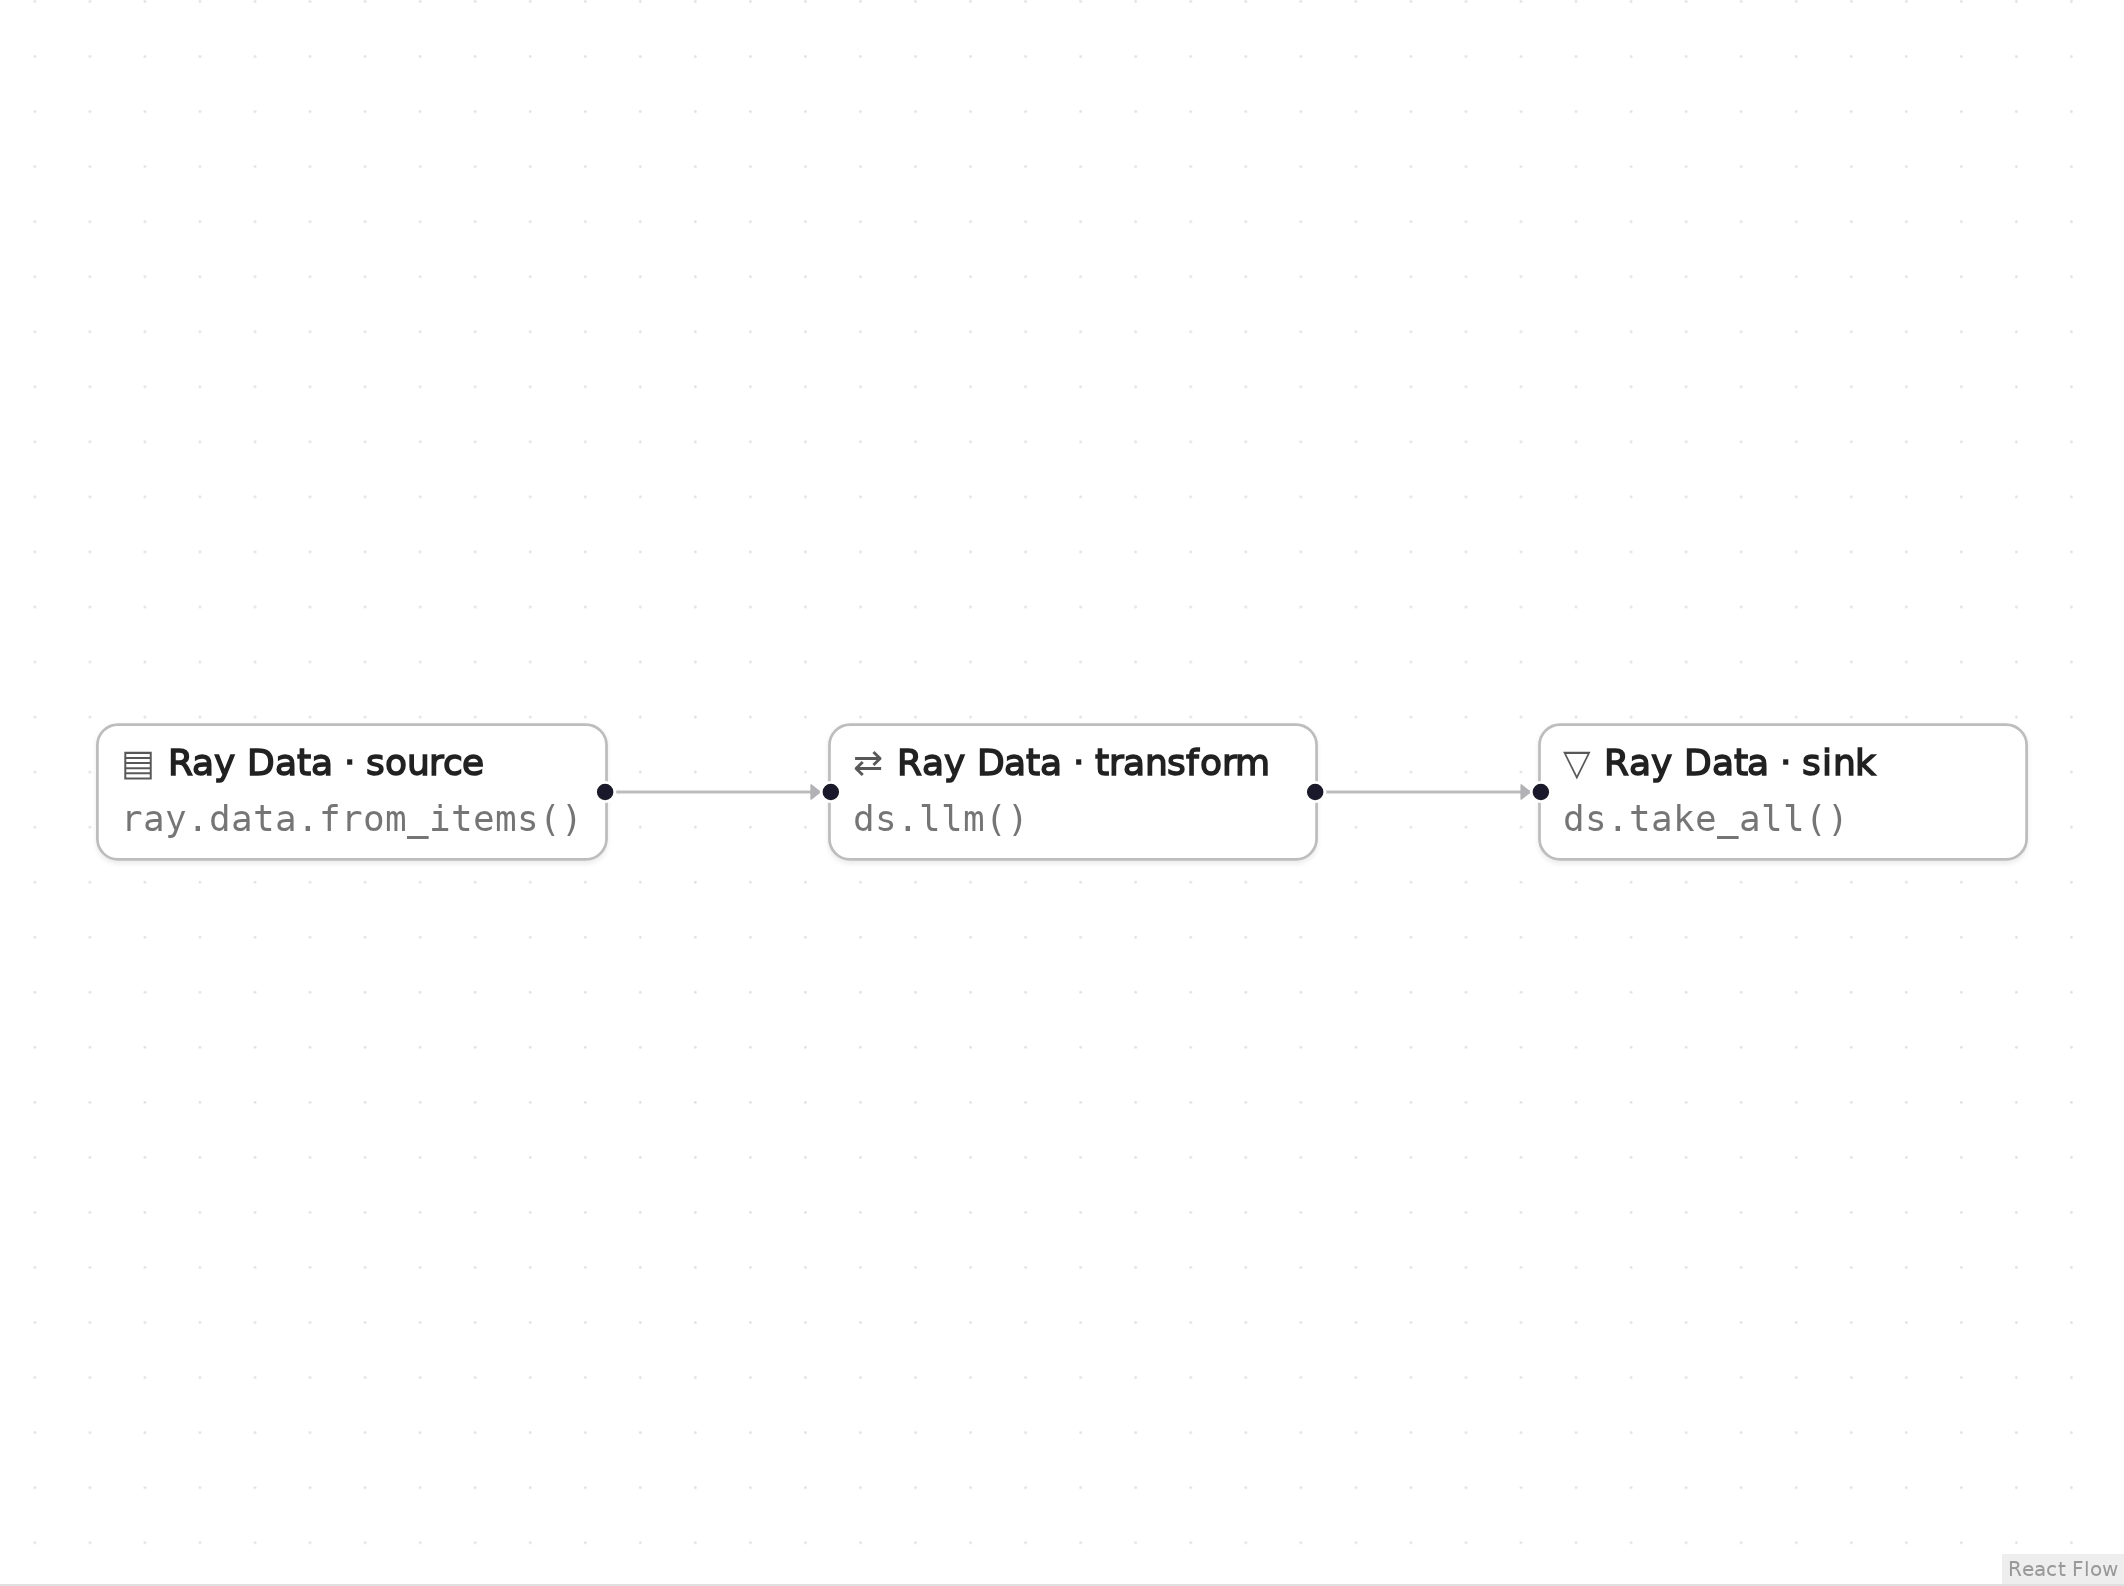

*The graph in Eugo's visual Ray builder.* The node's caption, `ds.llm()`, is the builder's shorthand, not a Ray Dataset method; the real Ray calls are in the generated code below.

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is not capped at a CPU count here, so it can see the machine's GPUs. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [ ]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR")

## User functions

This pattern needs no user functions: the pre- and post-processing are lambdas in the llm node.

## Generated code

This is the cell the visual builder generated from the graph above.

In [ ]:
# Generated with Eugo's visual Ray builder

import ray
from ray.data.llm import build_processor, vLLMEngineProcessorConfig

if not ray.is_initialized():
    ray.init()

ds = ray.data.from_items([{"prompt": "What is Ray?"}, {"prompt": "What is a DAG?"}])
_llm_processor_n2 = build_processor(vLLMEngineProcessorConfig(model_source="Qwen/Qwen2.5-0.5B-Instruct", concurrency=1, batch_size=8), preprocess=lambda row: dict(messages=[{"role": "user", "content": row["prompt"]}], sampling_params=dict(max_tokens=64)), postprocess=lambda row: dict(answer=row["generated_text"]))
ds = _llm_processor_n2(ds)
answers = ds.take_all()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [ ]:
assert len(answers) == 2, answers
for row in answers:
    print(row["answer"])

## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.data.llm import build_processor, vLLMEngineProcessorConfig
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 9)

```python
ds = ray.data.from_items([{"prompt": "What is Ray?"}, {"prompt": "What is a DAG?"}])
```

Two prompts as rows.

**Transform** (node `n2`, lines 10–11)

```python
_llm_processor_n2 = build_processor(vLLMEngineProcessorConfig(model_source="Qwen/Qwen2.5-0.5B-Instruct", concurrency=1, batch_size=8), preprocess=lambda row: dict(messages=[{"role": "user", "content": row["prompt"]}], sampling_params=dict(max_tokens=64)), postprocess=lambda row: dict(answer=row["generated_text"]))
ds = _llm_processor_n2(ds)
```

build_processor wraps a vLLM engine config; preprocess turns each row into chat messages and postprocess keeps only the generated text.

**Sink** (node `n3`, line 12)

```python
answers = ds.take_all()
```

take_all() runs inference and collects the answers.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [ ]:
ray.shutdown()